# TASK 1: Used Car Price Prediction Using Linear Regression

## Step 1: Import Libraries

In [1]:

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

## Step 2: Load the Dataset

In [3]:

df = pd.read_csv("data.csv")

df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## Step 3: Inspect the Dataset

In [5]:
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 451
Number of columns: 9


In [7]:
print(df.columns.tolist())


['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 451 entries, 0 to 450
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       451 non-null    object 
 1   Year           451 non-null    int64  
 2   Selling_Price  451 non-null    float64
 3   Present_Price  451 non-null    float64
 4   Kms_Driven     451 non-null    int64  
 5   Fuel_Type      451 non-null    object 
 6   Seller_Type    451 non-null    object 
 7   Transmission   451 non-null    object 
 8   Owner          451 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 31.8+ KB


In [9]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Car_Name,451,98,city,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,451.0,NaN,NaN,NaN,2012.51663,3.783774,2003.0,2010.0,2014.0,2015.0,2018.0
Selling_Price,451.0,NaN,NaN,NaN,4.046718,4.638668,0.1,0.75,2.9,5.5,35.0
Present_Price,451.0,NaN,NaN,NaN,7.941641,8.382598,0.32,1.47,6.79,10.09,92.6
Kms_Driven,451.0,NaN,NaN,NaN,43885.822616,38341.086312,500.0,17750.0,37000.0,60038.0,500000.0
Fuel_Type,451,3,Petrol,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Seller_Type,451,2,Dealer,288,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,451,2,Manual,389,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,451.0,NaN,NaN,NaN,0.044346,0.262945,0.0,0.0,0.0,0.0,3.0


## Step 4: Data Understanding

In [10]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Series([], dtype: int64)


In [11]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 2


In [12]:
for column in df.columns:
    print(f"\n{column}")
    print("Unique values:", df[column].nunique())
    print(df[column].unique()[:10])


Car_Name
Unique values: 98
['ritz' 'sx4' 'ciaz' 'wagon r' 'swift' 'vitara brezza' 's cross'
 'alto 800' 'ertiga' 'dzire']

Year
Unique values: 16
[2014 2013 2017 2011 2018 2015 2016 2009 2010 2012]

Selling_Price
Unique values: 259
[3.35 4.75 7.25 2.85 4.6  9.25 6.75 6.5  8.75 7.45]

Present_Price
Unique values: 271
[5.59 9.54 9.85 4.15 6.87 9.83 8.12 8.61 8.89 8.92]

Kms_Driven
Unique values: 350
[27000 43000  6900  5200 42450  2071 18796 33429 20273 42367]

Fuel_Type
Unique values: 3
['Petrol' 'Diesel' 'CNG']

Seller_Type
Unique values: 2
['Dealer' 'Individual']

Transmission
Unique values: 2
['Manual' 'Automatic']

Owner
Unique values: 3
[0 1 3]


## Step 5: Exploratory Data Analysis (EDA)

In [13]:
print(df.columns.tolist())

['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']


In [14]:
target = "Selling_Price"

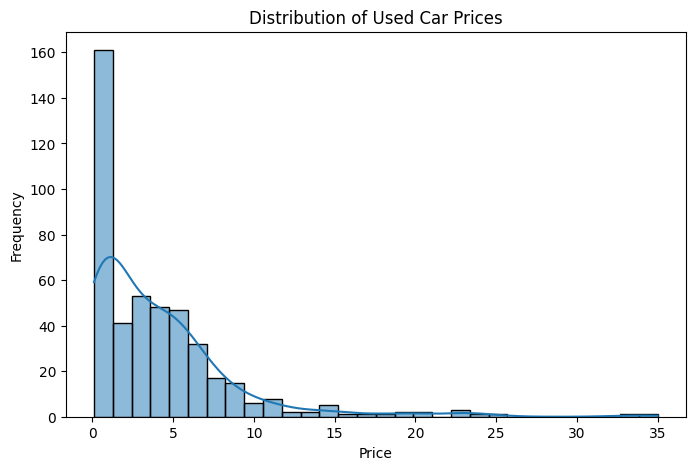

In [15]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df[target].dropna(),
    kde=True,
    bins=30
)

plt.title("Distribution of Used Car Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

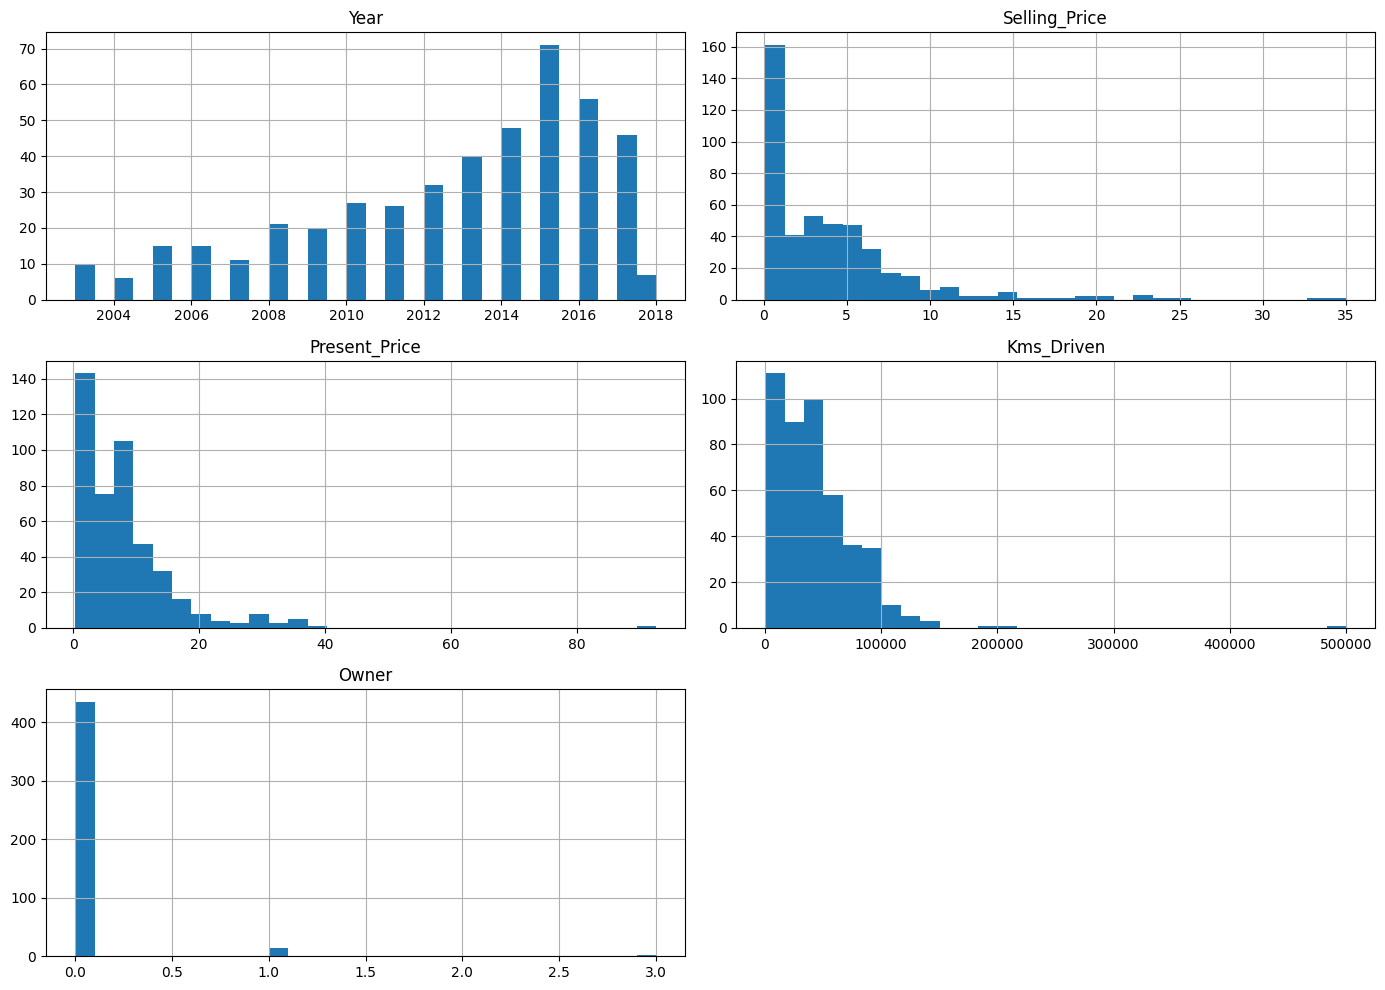

In [16]:
df.select_dtypes(include=np.number).hist(
    figsize=(14, 10),
    bins=30
)

plt.tight_layout()
plt.show()

In [17]:
categorical_columns = df.select_dtypes(
    include="object"
).columns

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts().head(10))


Car_Name
Car_Name
city                         36
corolla altis                25
verna                        22
fortuner                     19
brio                         18
innova                       17
Royal Enfield Classic 350    14
ciaz                         14
i20                          13
ertiga                       12
Name: count, dtype: int64

Fuel_Type
Fuel_Type
Petrol    364
Diesel     84
CNG         3
Name: count, dtype: int64

Seller_Type
Seller_Type
Dealer        288
Individual    163
Name: count, dtype: int64

Transmission
Transmission
Manual       389
Automatic     62
Name: count, dtype: int64


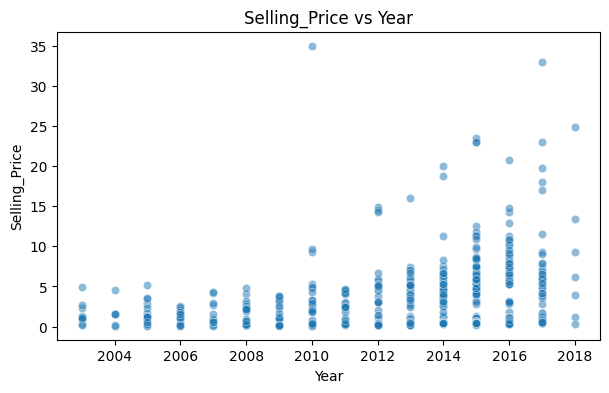

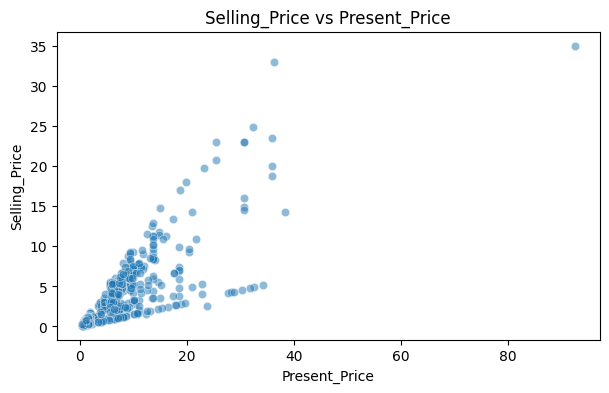

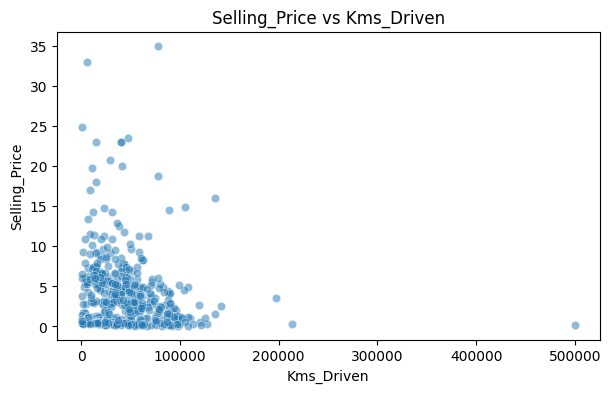

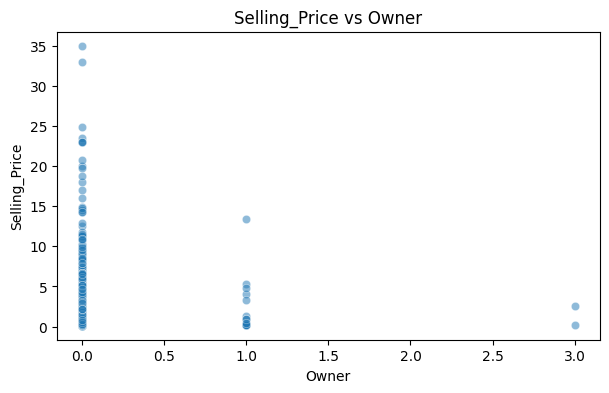

In [18]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

numeric_features = [
    col for col in numeric_columns
    if col != target
]

for column in numeric_features:
    plt.figure(figsize=(7, 4))

    sns.scatterplot(
        data=df,
        x=column,
        y=target,
        alpha=0.5
    )

    plt.title(f"{target} vs {column}")
    plt.show()

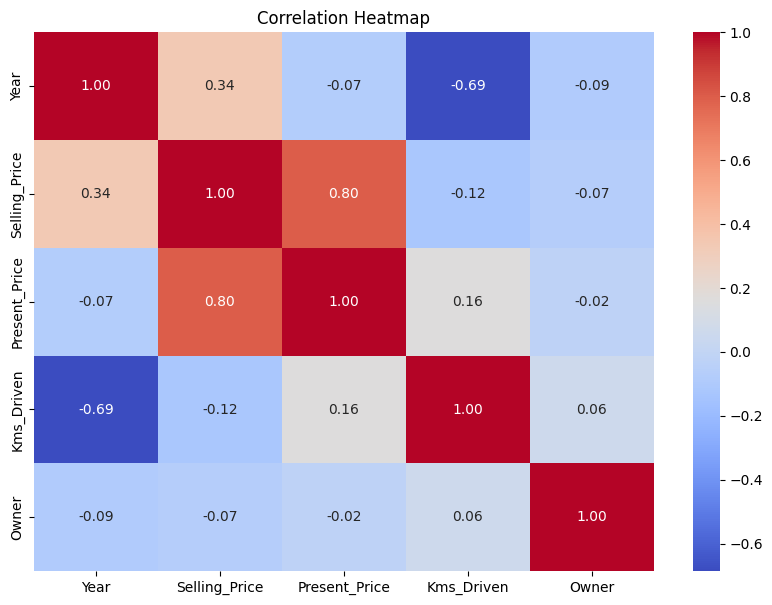

In [19]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

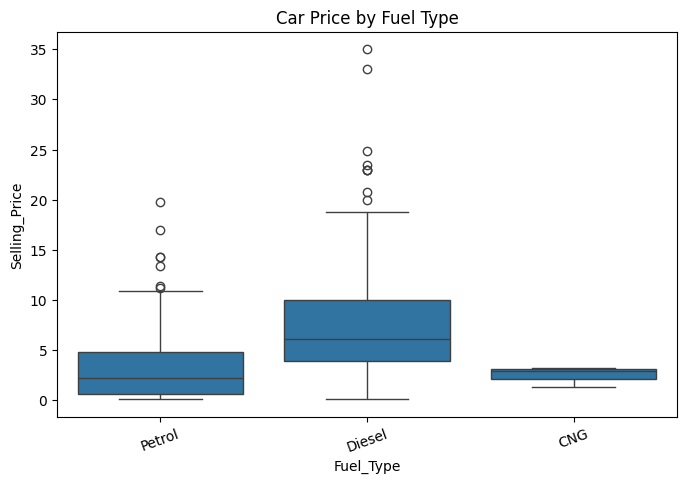

In [20]:
if "Fuel_Type" in df.columns:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="Fuel_Type",
        y=target
    )

    plt.title("Car Price by Fuel Type")
    plt.xticks(rotation=20)
    plt.show()

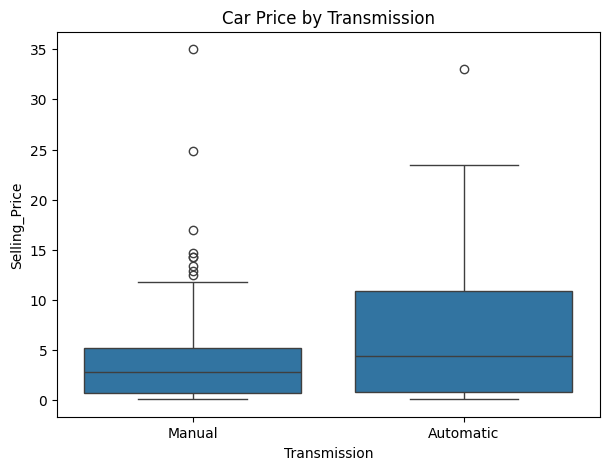

In [21]:
if "Transmission" in df.columns:
    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=df,
        x="Transmission",
        y=target
    )

    plt.title("Car Price by Transmission")
    plt.show()

## Step 6: Data Wrangling and Cleaning

In [23]:
df.columns = (
    df.columns
    .str.strip()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']


In [24]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (449, 9)


In [25]:
df[target] = (
    df[target]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace(r"[^\d.\-]", "", regex=True)
)

df[target] = pd.to_numeric(
    df[target],
    errors="coerce"
)

df = df.dropna(subset=[target])

df = df[df[target] > 0]

print(df[target].describe())

count    449.000000
mean       3.996258
std        4.558321
min        0.100000
25%        0.750000
50%        2.900000
75%        5.500000
max       35.000000
Name: Selling_Price, dtype: float64


In [26]:
measurement_columns = [
    "Mileage",
    "Engine",
    "Power",
    "New_Price"
]

for column in measurement_columns:
    if column in df.columns:

        df[column] = pd.to_numeric(
            df[column].astype(str)
            .str.extract(r"([-+]?\d*\.?\d+)")[0],
            errors="coerce"
        )

df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [27]:
if "Kilometers_Driven" in df.columns:
    df = df[df["Kilometers_Driven"] >= 0]

if "Year" in df.columns:
    df["Year"] = pd.to_numeric(
        df["Year"],
        errors="coerce"
    )

    df = df[
        df["Year"].between(1950, 2026)
    ]

print("Shape after basic cleaning:", df.shape)

Shape after basic cleaning: (449, 9)


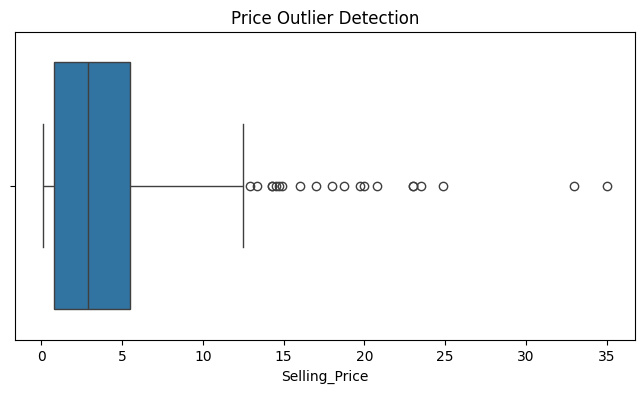

In [28]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df[target])

plt.title("Price Outlier Detection")
plt.show()

## Step 7: Feature Engineering

In [29]:
if "Year" in df.columns:
    df["Car_Age"] = 2026 - df["Year"]

df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,12
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,13
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,9
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0,15
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0,12


In [30]:
if "Name" in df.columns:
    df["Brand"] = (
        df["Name"]
        .astype(str)
        .str.strip()
        .str.split()
        .str[0]
    )

    df = df.drop(columns=["Name"])

df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,12
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,13
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,9
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0,15
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0,12


In [31]:
X = df.drop(columns=[target])
y = df[target]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (449, 9)
Target shape: (449,)


## Step 8: Prepare Data for Linear Regression

In [32]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['Year', 'Present_Price', 'Kms_Driven', 'Owner', 'Car_Age']
Categorical features: ['Car_Name', 'Fuel_Type', 'Seller_Type', 'Transmission']


In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (359, 9)
Testing data: (90, 9)


In [34]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

## Step 9: Implement Linear Regression

In [36]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

In [37]:
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [38]:
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Training predictions:", y_train_pred[:5])
print("Testing predictions:", y_test_pred[:5])

Training predictions: [4.77829518 6.63530837 0.35003697 5.34547332 5.36940302]
Testing predictions: [6.08276562 3.61350173 0.16461058 8.63052762 5.01973876]


## Step 10: Evaluate Linear Regression

In [39]:
def evaluate_model(y_true, y_pred):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    mse = mean_squared_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_true,
        y_pred
    )

    return mae, mse, rmse, r2

In [40]:
train_mae, train_mse, train_rmse, train_r2 = (
    evaluate_model(y_train, y_train_pred)
)

print("Training Results")
print("----------------")
print("MAE:", train_mae)
print("MSE:", train_mse)
print("RMSE:", train_rmse)
print("R2 Score:", train_r2)

Training Results
----------------
MAE: 0.9965978087275108
MSE: 2.574566152799879
RMSE: 1.6045454661055507
R2 Score: 0.8826464359441649


In [41]:
test_mae, test_mse, test_rmse, test_r2 = (
    evaluate_model(y_test, y_test_pred)
)

print("Testing Results")
print("----------------")
print("MAE:", test_mae)
print("MSE:", test_mse)
print("RMSE:", test_rmse)
print("R2 Score:", test_r2)

Testing Results
----------------
MAE: 1.4440096263857602
MSE: 4.15753324234497
RMSE: 2.039003002044129
R2 Score: 0.7377495469563384


In [42]:
metrics_df = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2 Score"],
    "Training": [
        train_mae, train_mse, train_rmse, train_r2
    ],
    "Testing": [
        test_mae, test_mse, test_rmse, test_r2
    ]
})

print(metrics_df)

     Metric  Training   Testing
0       MAE  0.996598  1.444010
1       MSE  2.574566  4.157533
2      RMSE  1.604545  2.039003
3  R2 Score  0.882646  0.737750


## Step 11: Plot Training and Testing Results

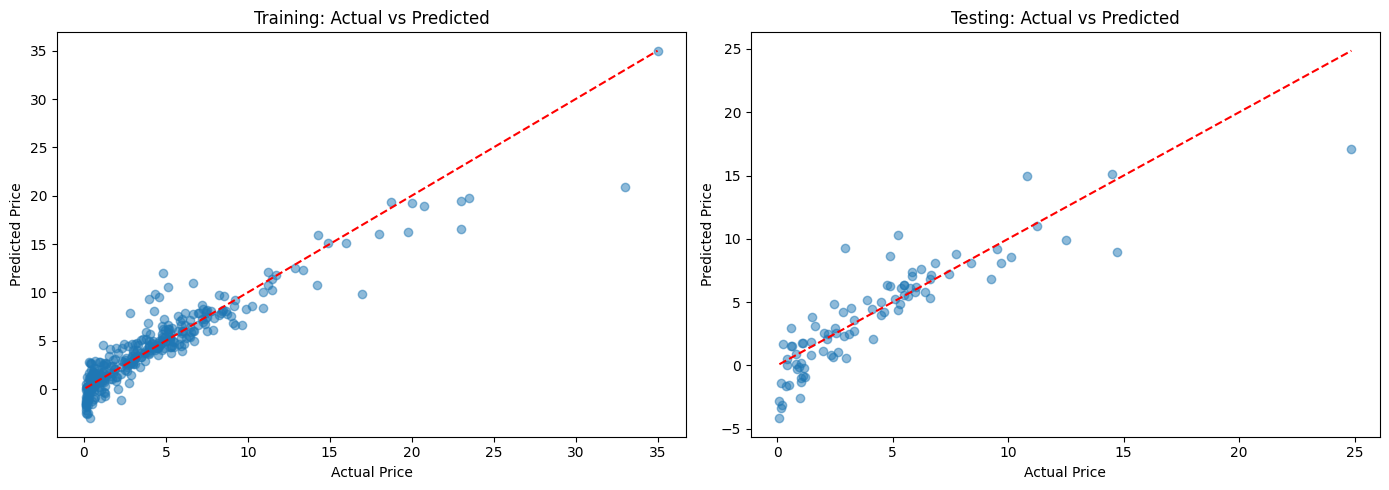

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Training results
axes[0].scatter(
    y_train,
    y_train_pred,
    alpha=0.5
)

axes[0].plot(
    [y_train.min(), y_train.max()],
    [y_train.min(), y_train.max()],
    "r--"
)

axes[0].set_title("Training: Actual vs Predicted")
axes[0].set_xlabel("Actual Price")
axes[0].set_ylabel("Predicted Price")

# Testing results
axes[1].scatter(
    y_test,
    y_test_pred,
    alpha=0.5
)

axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

axes[1].set_title("Testing: Actual vs Predicted")
axes[1].set_xlabel("Actual Price")
axes[1].set_ylabel("Predicted Price")

plt.tight_layout()
plt.show()

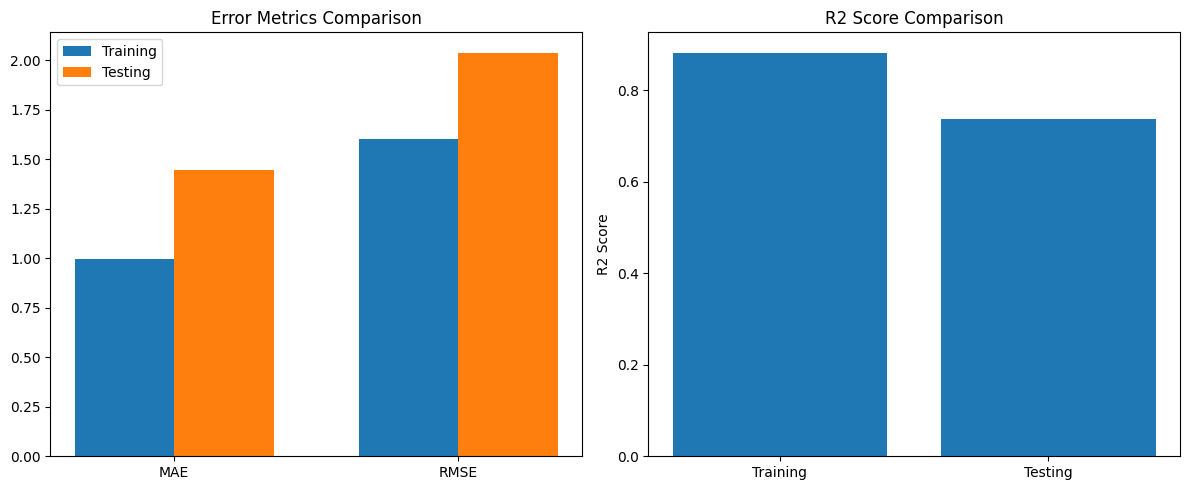

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Error metrics
error_metrics = ["MAE", "RMSE"]

train_errors = [train_mae, train_rmse]
test_errors = [test_mae, test_rmse]

x = np.arange(len(error_metrics))
width = 0.35

axes[0].bar(
    x - width / 2,
    train_errors,
    width,
    label="Training"
)

axes[0].bar(
    x + width / 2,
    test_errors,
    width,
    label="Testing"
)

axes[0].set_xticks(x)
axes[0].set_xticklabels(error_metrics)
axes[0].set_title("Error Metrics Comparison")
axes[0].legend()

# R2 comparison
axes[1].bar(
    ["Training", "Testing"],
    [train_r2, test_r2]
)

axes[1].set_title("R2 Score Comparison")
axes[1].set_ylabel("R2 Score")

plt.tight_layout()
plt.show()

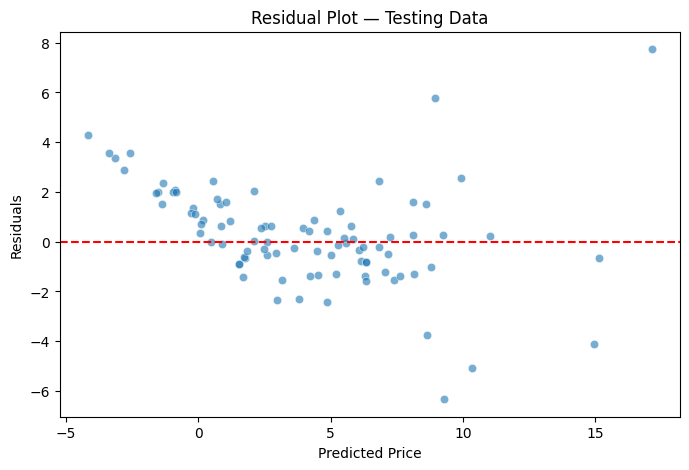

In [45]:
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_test_pred,
    y=residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Residual Plot — Testing Data")
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.show()

## Step 12: Analyze Model Coefficients

In [46]:
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

coefficients = model.named_steps[
    "regressor"
].coef_

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df["Absolute_Coefficient"] = (
    coef_df["Coefficient"].abs()
)

coef_df = coef_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

print(coef_df.head(15))

                                    Feature  Coefficient  Absolute_Coefficient
89               cat__Car_Name_land cruiser   -19.930885             19.930885
69                      cat__Car_Name_camry   -10.121391             10.121391
82                   cat__Car_Name_fortuner    -5.309943              5.309943
1                        num__Present_Price     5.146445              5.146445
32        cat__Car_Name_Hero Super Splendor     4.962375              4.962375
27                  cat__Car_Name_Hero Hunk     3.500872              3.500872
72              cat__Car_Name_corolla altis    -2.668017              2.668017
18           cat__Car_Name_Bajaj Pulsar 150     2.607027              2.607027
12     cat__Car_Name_Bajaj Avenger 220 dtsi     2.499538              2.499538
39           cat__Car_Name_Honda CB twister     2.465482              2.465482
36             cat__Car_Name_Honda CB Shine     2.465183              2.465183
50  cat__Car_Name_Royal Enfield Classic 500     2.24

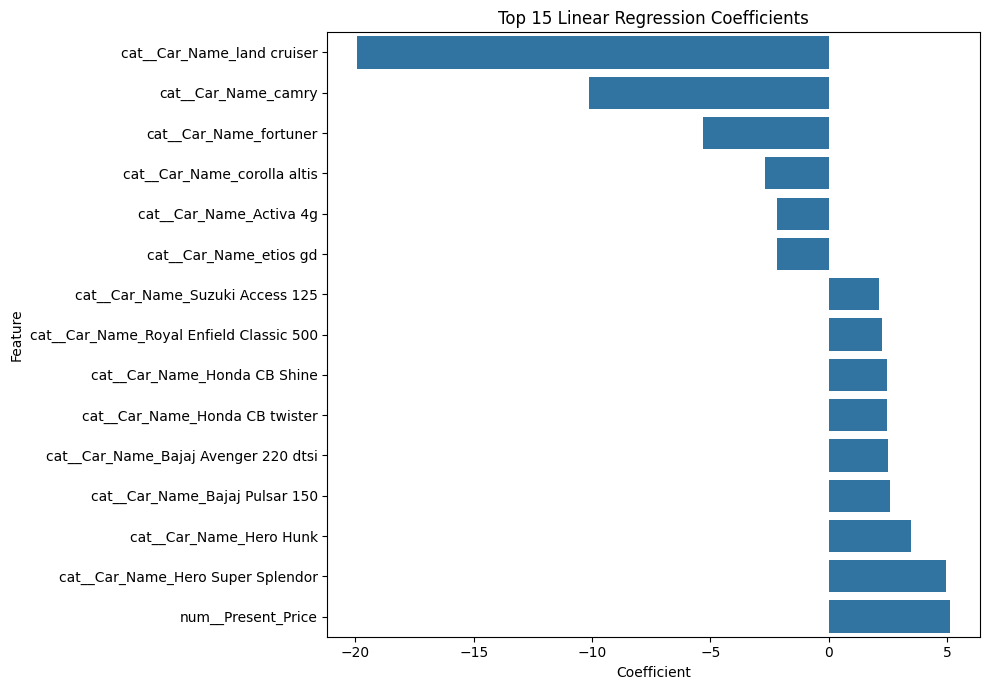

In [47]:
top_features = coef_df.head(15).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature"
)

plt.title("Top 15 Linear Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Step 13: Final Conclusion

### Conclusion

In this task, we developed a Linear Regression model to predict used car prices using a dataset of Indian used cars. We performed data inspection, exploratory data analysis, data cleaning, missing-value handling, feature engineering and categorical encoding before training the model.

The dataset was divided into training and testing sets. Linear Regression was trained on the training data and evaluated on unseen testing data using MAE, MSE, RMSE and R
2
. We also visualized actual versus predicted prices, compared training and testing performance and analyzed the residuals and model coefficients.

The final performance of the model will be determined by the metrics generated from the actual downloaded dataset. The results can help assess whether a linear relationship is sufficient for estimating used car prices or whether more flexible regression algorithms should also be explored.

# TASK 2: Household Electricity Consumption Prediction (Linear Regression)
---

## 1. Review the Dataset

Since the target variable is continuous, this is a regression problem. Linear Regression can be considered, but its suitability depends on whether the data satisfies its assumptions.

---

## 2. Linear Regression Assumptions

## 3. Assumption Analysis

* 3.1 Linearity
* 3.2 Independence of observations
* 3.3 Homoscedasticity
* 3.4 Normality of residuals
* 3.5 Absence of perfect multicollinearity

---

## 4. Perform the Assumption Analysis

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data.csv")

print(df.head())
print(df.info())
print(df.describe())
print(df.isnull().sum())

   record_id  customer_id            timestamp  hour  day_of_week  month  \
0        667        10001  2025-01-28 18:00:00    18            1      1   
1        778        10001  2025-02-02 09:00:00     9            6      2   
2       1011        10001  2025-02-12 02:00:00     2            2      2   
3       1170        10001  2025-02-18 17:00:00    17            1      2   
4       2037        10001  2025-03-26 20:00:00    20            2      3   

   is_weekend  season     customer_type  age  ...  ev_charging_kwh  \
0           0  Winter  Small_Commercial   66  ...            0.000   
1           1  Winter       Residential   38  ...            0.000   
2           0  Winter       Residential   26  ...            1.225   
3           0  Winter       Residential   59  ...            0.000   
4           0  Spring       Residential   38  ...            0.000   

   electricity_consumption_kwh  pricing_influence_score  \
0                        2.058                    11.39   
1   

In [8]:
features = [
    "household_size",
    "monthly_income_usd",
    "home_area_sqft"
]

target = "electricity_consumption_kwh"

X = df[features]
y = df[target]

print("Features:", X.columns.tolist())
print("Target:", y.name)

Features: ['household_size', 'monthly_income_usd', 'home_area_sqft']
Target: electricity_consumption_kwh


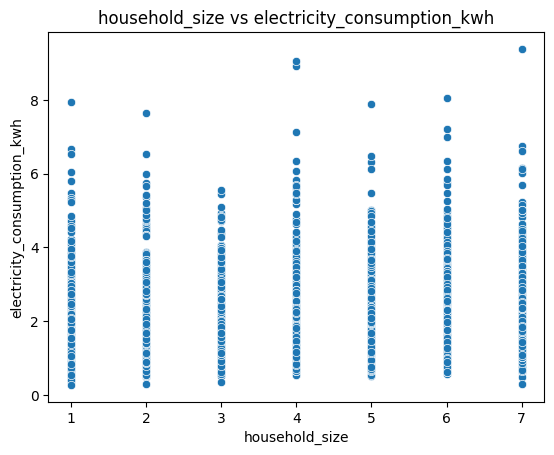

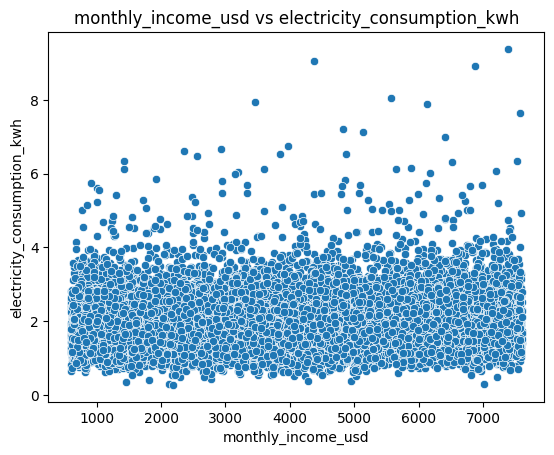

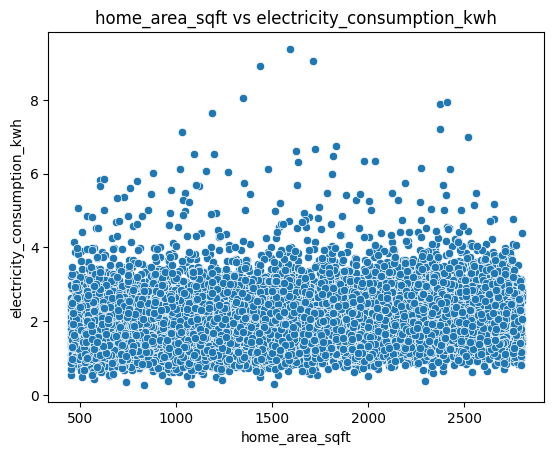

In [9]:
for feature in features:

    sns.scatterplot(
        data=df,
        x=feature,
        y=target
    )

    plt.title(f"{feature} vs {target}")
    plt.show()

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

residuals = y_test - y_pred

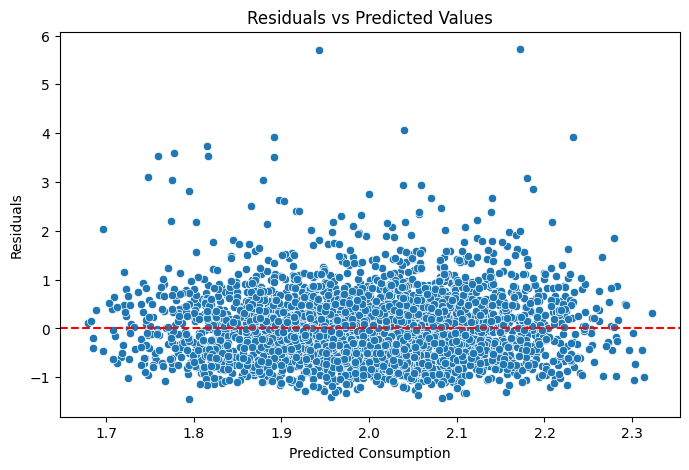

In [11]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_pred,
    y=residuals
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Consumption")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Values")
plt.show()

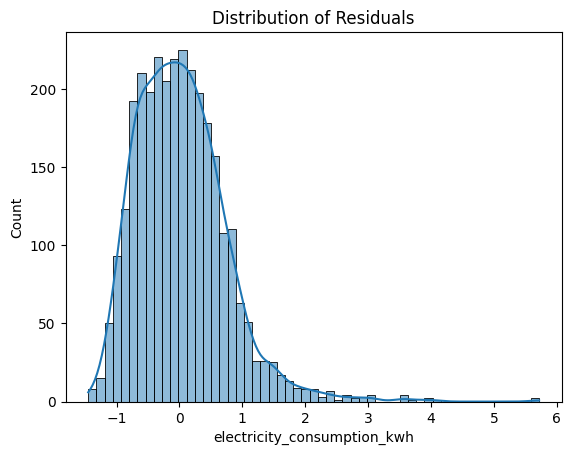

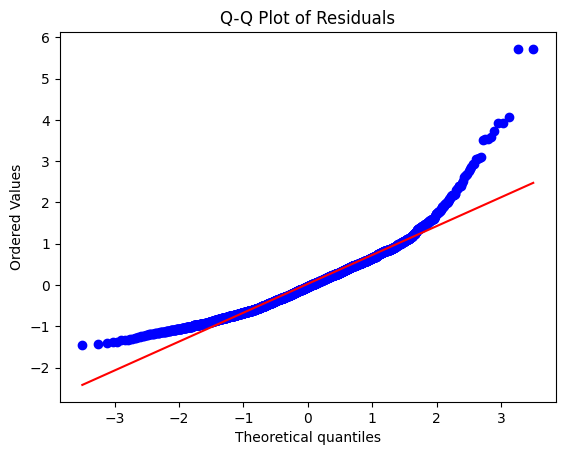

In [12]:
import scipy.stats as stats

sns.histplot(
    residuals,
    kde=True
)

plt.title("Distribution of Residuals")
plt.show()

stats.probplot(
    residuals,
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Residuals")
plt.show()

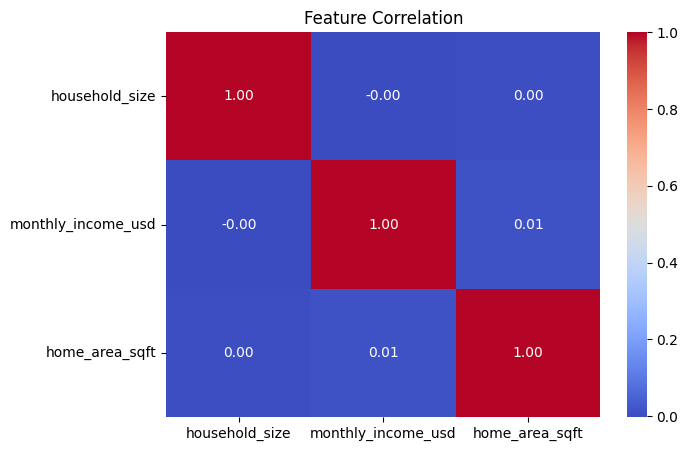

In [13]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    X.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation")
plt.show()

In [14]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = X.astype(float).dropna()

vif_df = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(
            X_vif.values, i
        )
        for i in range(X_vif.shape[1])
    ]
})

print(vif_df)

              Feature       VIF
0      household_size  1.000020
1  monthly_income_usd  1.000098
2      home_area_sqft  1.000103


## 5. Decision

* ### Linear Regression is a reasonable model to test

Based on the described numerical features and continuous target, Linear Regression is a suitable candidate for an initial analysis. However, the dataset description alone cannot establish that all its assumptions are satisfied. The scatterplots, residual diagnostics, observation structure and multicollinearity checks must be examined before reaching a final conclusion.